# Byte Pair Encoding (BPE) from Scratch
**Project:** Tokenization & Context Window Analyzer, Phase 0

This notebook has three parts:
1. **BPE training, step by step** (character level, so every merge is easy to read).
2. **A real tokenizer**: byte-level BPE with `train`, `encode`, `decode`, token IDs and special tokens. This is the same idea GPT-2 and GPT-4 use.
3. **Tests and an experiment**: round-trip tests, and a plot of *tokens vs. number of merges*.

In [1]:
import matplotlib.pyplot as plt
from collections import Counter
import re

## BPE training, step by step

In [1]:
END = "</w>"   # end-of-word marker: lets the model tell "est" inside a word from "est" at the end

def initialize_vocabulary(corpus):
    """Split every word into characters + END. Returns {word_as_tuple: frequency}."""
    vocab = Counter()
    for sentence in corpus:
        for word in sentence.split():
            vocab[tuple(word) + (END,)] += 1
    return dict(vocab)

def get_pair_frequencies(vocab):
    """Count every adjacent pair, weighted by how often its word appears."""
    pairs = Counter()
    for word, freq in vocab.items():
        for pair in zip(word, word[1:]):
            pairs[pair] += freq
    return pairs

def get_most_frequent_pair(pairs):
    """Highest count wins. Ties are broken alphabetically, so training is deterministic."""
    if not pairs:
        return None
    return min(pairs, key=lambda p: (-pairs[p], p))

def merge_pair(word, pair):
    """Replace every occurrence of `pair` inside one word."""
    out, i = [], 0
    while i < len(word):
        if i < len(word) - 1 and (word[i], word[i + 1]) == pair:
            out.append(word[i] + word[i + 1])
            i += 2
        else:
            out.append(word[i])
            i += 1
    return tuple(out)

def update_vocabulary(vocab, pair):
    new_vocab = Counter()
    for word, freq in vocab.items():
        new_vocab[merge_pair(word, pair)] += freq
    return dict(new_vocab)

def train_bpe(corpus, num_merges, verbose=True):
    """Learn `num_merges` merge rules. Returns (final_vocab, ordered_merges)."""
    vocab, merges = initialize_vocabulary(corpus), []
    for step in range(1, num_merges + 1):
        pairs = get_pair_frequencies(vocab)
        best = get_most_frequent_pair(pairs)
        if best is None:          # every word is already a single token
            break
        vocab = update_vocabulary(vocab, best)
        merges.append(best)
        if verbose:
            print(f"Merge {step}: {best}  (count {pairs[best]})")
            print("   ", {" ".join(w): f for w, f in vocab.items()})
    return vocab, merges

### Walk-through on the classic corpus
Words: `low lower lowest newest widest`. At the start **five pairs tie with count 3** (`l+o`, `o+w`, `w+e`, `e+s`, `s+t`), so the tie-break rule decides what happens. Here the rule picks `e+s` first.

In [2]:
corpus = ["low lower lowest newest widest"]
final_vocab, merges = train_bpe(corpus, 8)

Merge 1: ('e', 's')  (count 3)
    {'l o w </w>': 1, 'l o w e r </w>': 1, 'l o w es t </w>': 1, 'n e w es t </w>': 1, 'w i d es t </w>': 1}
Merge 2: ('es', 't')  (count 3)
    {'l o w </w>': 1, 'l o w e r </w>': 1, 'l o w est </w>': 1, 'n e w est </w>': 1, 'w i d est </w>': 1}
Merge 3: ('est', '</w>')  (count 3)
    {'l o w </w>': 1, 'l o w e r </w>': 1, 'l o w est</w>': 1, 'n e w est</w>': 1, 'w i d est</w>': 1}
Merge 4: ('l', 'o')  (count 3)
    {'lo w </w>': 1, 'lo w e r </w>': 1, 'lo w est</w>': 1, 'n e w est</w>': 1, 'w i d est</w>': 1}
Merge 5: ('lo', 'w')  (count 3)
    {'low </w>': 1, 'low e r </w>': 1, 'low est</w>': 1, 'n e w est</w>': 1, 'w i d est</w>': 1}
Merge 6: ('d', 'est</w>')  (count 1)
    {'low </w>': 1, 'low e r </w>': 1, 'low est</w>': 1, 'n e w est</w>': 1, 'w i dest</w>': 1}
Merge 7: ('e', 'r')  (count 1)
    {'low </w>': 1, 'low er </w>': 1, 'low est</w>': 1, 'n e w est</w>': 1, 'w i dest</w>': 1}
Merge 8: ('e', 'w')  (count 1)
    {'low </w>': 1, 'low er </w>'

### Encoding new text with the learned merges (character level)

In [3]:
def encode_word(word, merges):
    tokens = tuple(word) + (END,)
    for pair in merges:                 # order matters!
        tokens = merge_pair(tokens, pair)
    return list(tokens)

for w in ["lowest", "newer", "widest", "slowest"]:
    print(f"{w:>8} -> {encode_word(w, merges)}")

  lowest -> ['low', 'est</w>']
   newer -> ['n', 'ew', 'er', '</w>']
  widest -> ['w', 'i', 'dest</w>']
 slowest -> ['s', 'low', 'est</w>']


`slowest` was never in the training data, yet it becomes `s | low | est</w>` and nothing is "unknown". This is why subword tokenizers fix the out-of-vocabulary problem.

**Limits of this version:** it throws away spaces (`split()`), and a character it has never seen (like `😊`) has no token. The next part fixes both.

## A real tokenizer: byte-level BPE
Two changes make it lossless:
- Start from the **256 byte values** instead of characters, so any text can be encoded (no unknown tokens).
- Use a **regex pre-tokenizer** that keeps leading spaces, so `decode(encode(text)) == text`.

In [ ]:
"""Minimal byte-level BPE tokenizer (GPT-2 style, simplified).

Pipeline:  text -> pre-tokens (regex) -> UTF-8 bytes -> apply learned merges -> ids
Because the base vocabulary is all 256 byte values, ANY text (Arabic, emoji,
code, odd whitespace) can be encoded, and decode(encode(text)) == text.
"""
PRETOKEN = re.compile(r" ?\w+| ?[^\w\s]+|\s+(?!\S)|\s+") # Pre-tokenizer: a word (with its leading space), punctuation/emoji run, or whitespace.

class BPETokenizer:
    def __init__(self, special_tokens=("<|endoftext|>",)):
        self.merges = {}            # (id_a, id_b) -> new_id, in learning order
        self.vocab = {i: bytes([i]) for i in range(256)}   # id -> bytes
        self.special = {}           # special token string -> id
        self._special_tokens = tuple(special_tokens)
        self._cache = {}

    # ---------- training ----------
    @staticmethod
    def _pair_counts(words):
        counts = Counter()
        for word, freq in words.items():
            for pair in zip(word, word[1:]):
                counts[pair] += freq
        return counts

    @staticmethod
    def _merge(word, pair, new_id):
        out, i = [], 0
        while i < len(word):
            if i < len(word) - 1 and (word[i], word[i + 1]) == pair:
                out.append(new_id)
                i += 2
            else:
                out.append(word[i])
                i += 1
        return tuple(out)

    def train(self, text, vocab_size, verbose=False):
        """Learn (vocab_size - 256) merges from `text`."""
        if vocab_size < 256:
            raise ValueError("vocab_size must be >= 256 (the byte alphabet)")
        pieces = Counter(PRETOKEN.findall(text))
        words = {tuple(p.encode("utf-8")): f for p, f in pieces.items()}
        for _ in range(vocab_size - 256):
            counts = self._pair_counts(words)
            if not counts:
                break
            # most frequent pair; ties -> smallest pair (deterministic)
            best = min(counts, key=lambda p: (-counts[p], p))
            new_id = 256 + len(self.merges)
            self.merges[best] = new_id
            self.vocab[new_id] = self.vocab[best[0]] + self.vocab[best[1]]
            words = {self._merge(w, best, new_id): f for w, f in words.items()}
            if verbose:
                print(f"merge {new_id - 255:>3}: {self.vocab[best[0]]!r} + "
                      f"{self.vocab[best[1]]!r} -> {self.vocab[new_id]!r}  (x{counts[best]})")
        for tok in self._special_tokens:          # special tokens get ids AFTER merges
            self.special[tok] = len(self.vocab)
            self.vocab[self.special[tok]] = tok.encode("utf-8")
        self._cache.clear()
        return self

    # ---------- encoding ----------
    def _encode_piece(self, piece):
        if piece in self._cache:
            return self._cache[piece]
        ids = list(piece.encode("utf-8"))
        while len(ids) >= 2:
            pairs = set(zip(ids, ids[1:]))
            # apply the merge that was learned EARLIEST (lowest new id)
            best = min(pairs, key=lambda p: self.merges.get(p, float("inf")))
            if best not in self.merges:
                break
            ids = list(self._merge(tuple(ids), best, self.merges[best]))
        self._cache[piece] = ids
        return ids

    def encode(self, text):
        if self.special:
            pattern = "(" + "|".join(re.escape(t) for t in self.special) + ")"
            parts = re.split(pattern, text)
        else:
            parts = [text]
        ids = []
        for part in parts:
            if part in self.special:
                ids.append(self.special[part])
            else:
                for piece in PRETOKEN.findall(part):
                    ids.extend(self._encode_piece(piece))
        return ids

    def decode(self, ids):
        raw = b"".join(self.vocab[i] for i in ids)
        return raw.decode("utf-8", errors="replace")

    def tokens(self, text):
        """Human-readable pieces. Partial UTF-8 bytes are shown as escapes."""
        return [self.vocab[i].decode("utf-8", errors="backslashreplace")
                for i in self.encode(text)]

    @property
    def vocab_size(self):
        return len(self.vocab)


### Train it on a small text and watch the merges

In [5]:
TRAIN_TEXT = """Tokenization turns text into tokens. A tokenizer splits text into subword tokens,
and each token has an id. Language models read token ids, not words. The tokenizer learns
frequent pieces such as ing, tion, the and token from a training corpus.
Lower, lowest, newer and newest share the pieces low, new, er and est.
""" * 10

tok = BPETokenizer().train(TRAIN_TEXT, vocab_size=300, verbose=False)
print("vocab size:", tok.vocab_size, "| merges:", len(tok.merges))
for (a, b), new_id in list(tok.merges.items())[:12]:
    print(f"id {new_id}: {tok.vocab[a]!r} + {tok.vocab[b]!r} -> {tok.vocab[new_id]!r}")

vocab size: 301 | merges: 44
id 256: b' ' + b't' -> b' t'
id 257: b'e' + b'n' -> b'en'
id 258: b'k' + b'en' -> b'ken'
id 259: b'o' + b'ken' -> b'oken'
id 260: b' t' + b'oken' -> b' token'
id 261: b' ' + b'a' -> b' a'
id 262: b' ' + b'i' -> b' i'
id 263: b'e' + b'r' -> b'er'
id 264: b'e' + b's' -> b'es'
id 265: b' ' + b'n' -> b' n'
id 266: b' ' + b's' -> b' s'
id 267: b'n' + b'd' -> b'nd'


### Encode and decode

In [6]:
for text in ["The tokenizer learns tokens", "lowest newest", "Hello 😊", "مرحبا"]:
    ids = tok.encode(text)
    print(f"{text!r}\n   ids    : {ids}\n   tokens : {tok.tokens(text)}\n   count  : {len(ids)}   decoded OK: {tok.decode(ids) == text}")

'The tokenizer learns tokens'
   ids    : [84, 271, 296, 263, 268, 269, 291, 295]
   tokens : ['T', 'he', ' tokeniz', 'er', ' l', 'ea', 'rns', ' tokens']
   count  : 8   decoded OK: True
'lowest newest'
   ids    : [108, 275, 277, 278, 277]
   tokens : ['l', 'ow', 'est', ' new', 'est']
   count  : 5   decoded OK: True
'Hello 😊'
   ids    : [72, 101, 108, 108, 111, 32, 240, 159, 152, 138]
   tokens : ['H', 'e', 'l', 'l', 'o', ' ', '\\xf0', '\\x9f', '\\x98', '\\x8a']
   count  : 10   decoded OK: True
'مرحبا'
   ids    : [217, 133, 216, 177, 216, 173, 216, 168, 216, 167]
   tokens : ['\\xd9', '\\x85', '\\xd8', '\\xb1', '\\xd8', '\\xad', '\\xd8', '\\xa8', '\\xd8', '\\xa7']
   count  : 10   decoded OK: True


**Reading the output.** English text that looks like the training text is compressed into a few tokens. The emoji and the Arabic word were **not** in the training text, so they fall back to raw bytes: 4 bytes for `😊`, 2 bytes per Arabic letter. This is a small model of a real effect: *languages that are rare in a tokenizer's training data cost more tokens.* You will measure it with real tokenizers in Phase 5.

## Tests and an experiment

In [7]:
tests = ["", "low", "  double  spaces ", "newest widest!", "مرحبا بالعالم", "Hello 😊",
         "def f(x):\n    return x**2\n", "<|endoftext|>after special"]
for t in tests:
    assert tok.decode(tok.encode(t)) == t, f"round trip failed for {t!r}"

assert len(tok.encode("lowest newest")) < len("lowest newest".encode())        # it compresses
assert len(tok.encode("😊")) == 4                                               # byte fallback
assert tok.encode("<|endoftext|>") == [tok.special["<|endoftext|>"]]          # special token = 1 id
assert BPETokenizer().train(TRAIN_TEXT, 280).merges == BPETokenizer().train(TRAIN_TEXT, 280).merges  # deterministic
print("All checks passed. Full pytest suite is in test_bpe.py")

All checks passed. Full pytest suite is in test_bpe.py


### Experiment: how many tokens as the vocabulary grows?

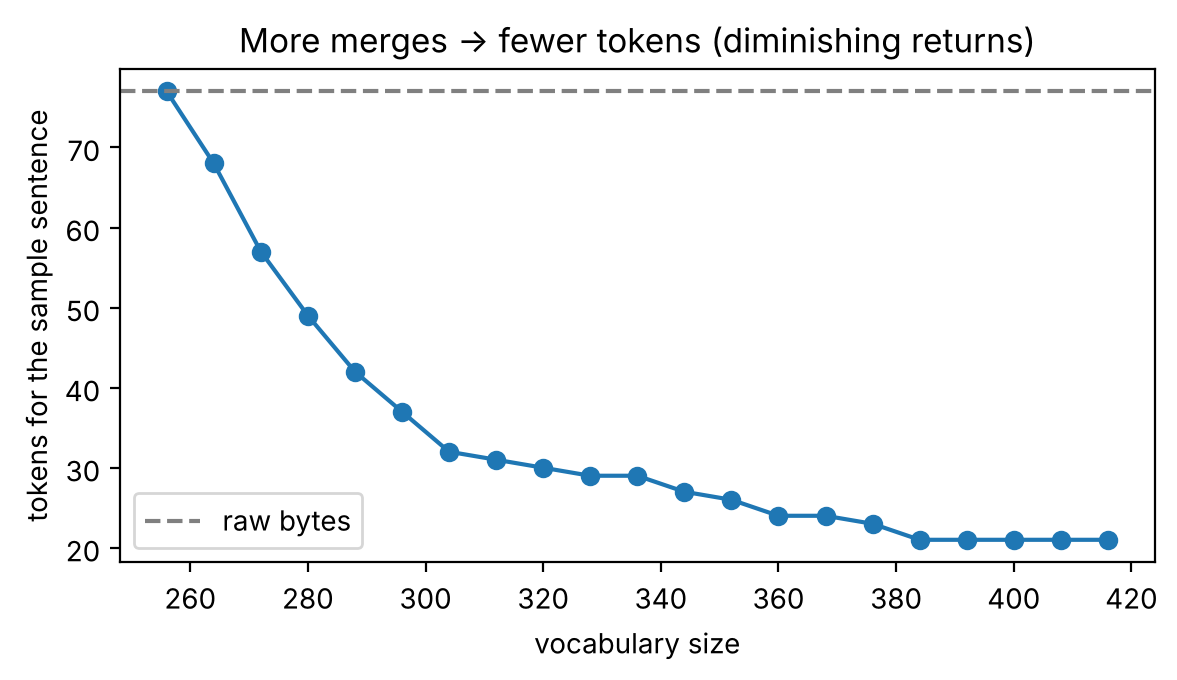

In [8]:
sample = "The tokenizer learns frequent pieces of text. Lowest and newest share pieces."
sizes = list(range(256, 421, 8))
counts = [len(BPETokenizer().train(TRAIN_TEXT, s).encode(sample)) for s in sizes]

plt.figure(figsize=(6, 3.5))
plt.plot(sizes, counts, marker="o")
plt.axhline(len(sample.encode()), ls="--", color="gray", label="raw bytes")
plt.xlabel("vocabulary size"); plt.ylabel("tokens for the sample sentence")
plt.title("More merges -> fewer tokens (diminishing returns)")
plt.legend(); plt.tight_layout(); plt.show()

**Take-away:** the curve drops fast and then flattens. Each extra vocabulary entry saves fewer tokens, but real models pay for every entry with a bigger embedding matrix. Choosing vocabulary size is a trade-off.